# Beer Servings: Regression Model Development

This notebook explores the provided dataset, compares regression models using held-out **R²**, tunes a Random Forest, selects the highest-scoring model, and saves it to `model.pkl` for Flask.

The target is `total_litres_of_pure_alcohol`. The five requested inputs are country, beer servings, spirit servings, wine servings and continent.

In [1]:
from pathlib import Path
import pickle
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

warnings.filterwarnings('ignore', category=UserWarning)
ROOT = Path.cwd()
DATA_PATH = ROOT / 'beer-servings.csv'
TARGET = 'total_litres_of_pure_alcohol'
NUMERIC_FEATURES = ['beer_servings', 'spirit_servings', 'wine_servings']
CATEGORICAL_FEATURES = ['country', 'continent']
FEATURES = CATEGORICAL_FEATURES + NUMERIC_FEATURES
print('Project directory:', ROOT)
print('Dataset:', DATA_PATH)

Project directory: C:\Users\MidhunWork\DSA 2026 files\Flask-Assignment
Dataset: C:\Users\MidhunWork\DSA 2026 files\Flask-Assignment\beer-servings.csv


## 1. Load and inspect the data
Check the dimensions, column types and sample rows before preparing model inputs.

In [2]:
df = pd.read_csv(DATA_PATH)
print(f'Rows: {len(df)} | Columns: {len(df.columns)}')
display(df.head())
print('Data types:')
display(df.dtypes.to_frame('dtype'))

Rows: 193 | Columns: 7


,Unnamed: 0,country,beer_servings,spirit_servings,wine_servings,total_litres_of_pure_alcohol,continent
0,0,Afghanistan,0.0,0.0,0.0,0.0,Asia
1,1,Albania,89.0,132.0,54.0,4.9,Europe
2,2,Algeria,25.0,0.0,14.0,0.7,Africa
3,3,Andorra,245.0,138.0,312.0,12.4,Europe
4,4,Angola,217.0,57.0,45.0,5.9,Africa


Data types:


,dtype
Unnamed: 0,int64
country,str
beer_servings,float64
spirit_servings,float64
wine_servings,float64
total_litres_of_pure_alcohol,float64
continent,str


## 2. Data quality and summary
Missing values are imputed inside the model pipeline so preprocessing is learned from training data only.

In [3]:
print('Missing values by column:')
display(df.isna().sum().to_frame('missing'))
print('Numeric summary:')
display(df[NUMERIC_FEATURES + [TARGET]].describe().round(2))
print('Unique countries:', df['country'].nunique())
print('Continents:', sorted(df['continent'].dropna().unique()))

Missing values by column:


,missing
Unnamed: 0,0
country,0
beer_servings,8
spirit_servings,8
wine_servings,6
total_litres_of_pure_alcohol,1
continent,0


Numeric summary:


,beer_servings,spirit_servings,wine_servings,total_litres_of_pure_alcohol
count,185.00,185.00,187.00,192.00
mean,105.12,83.22,50.17,4.74
std,100.52,89.14,80.36,3.77
min,0.00,0.00,0.00,0.00
25%,20.00,4.00,1.00,1.30
50%,76.00,60.00,9.00,4.25
75%,185.00,132.00,60.50,7.20
max,376.00,438.00,370.00,14.40


Unique countries: 193
Continents: ['Africa', 'Asia', 'Europe', 'North America', 'Oceania', 'South America']


## 3. Explore the target and continent averages
These charts are also saved as static assets for the Flask landing page.

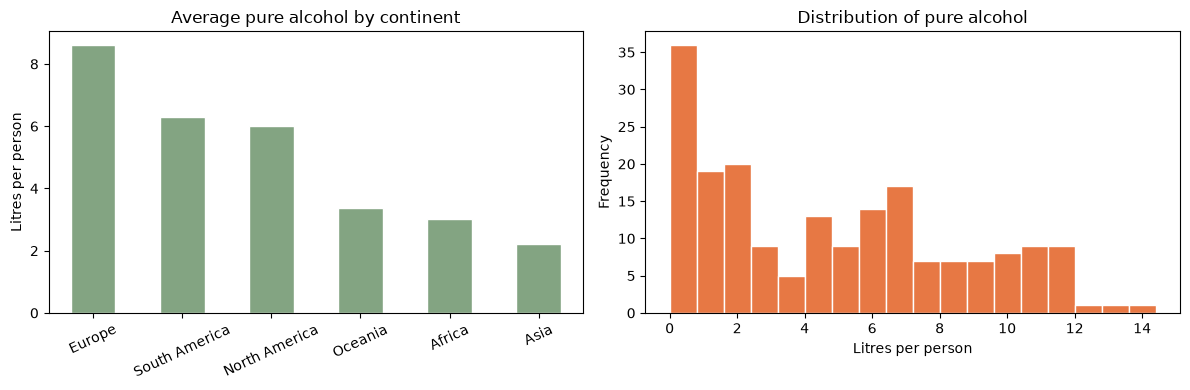

In [4]:
clean_for_charts = df.dropna(subset=[TARGET]).copy()
continent_means = clean_for_charts.groupby('continent')[TARGET].mean().sort_values(ascending=False)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
continent_means.plot(kind='bar', ax=axes[0], color='#83a482', edgecolor='white')
axes[0].set_title('Average pure alcohol by continent'); axes[0].set_ylabel('Litres per person'); axes[0].set_xlabel('')
axes[0].tick_params(axis='x', rotation=25)
clean_for_charts[TARGET].plot(kind='hist', bins=18, ax=axes[1], color='#e77844', edgecolor='white')
axes[1].set_title('Distribution of pure alcohol'); axes[1].set_xlabel('Litres per person')
fig.tight_layout(); fig.savefig(ROOT / 'static' / 'dataset_overview.png', dpi=160, bbox_inches='tight'); plt.show()

## 4. Prepare features and split the data
Use a fixed random seed for a reproducible 80/20 training/evaluation split. The evaluation set is held out from tuning.

In [5]:
model_data = df[FEATURES + [TARGET]].dropna(subset=[TARGET]).copy()
X = model_data[FEATURES]
y = model_data[TARGET]
X_train, X_eval, y_train, y_eval = train_test_split(X, y, test_size=0.20, random_state=42)
print(f'Training rows: {len(X_train)} | Evaluation rows: {len(X_eval)}')
print('Evaluation target mean:', round(y_eval.mean(), 3))

Training rows: 153 | Evaluation rows: 39
Evaluation target mean: 4.71


## 5. Build reusable preprocessing
Country and continent use one-hot encoding with safe handling of unseen categories; numeric fields use median imputation and scaling.

In [6]:
numeric_preprocess = Pipeline([('imputer', SimpleImputer(strategy='median')), ('scaler', StandardScaler())])
categorical_preprocess = Pipeline([('imputer', SimpleImputer(strategy='most_frequent')), ('onehot', OneHotEncoder(handle_unknown='ignore'))])
preprocessor = ColumnTransformer([('numeric', numeric_preprocess, NUMERIC_FEATURES), ('categorical', categorical_preprocess, CATEGORICAL_FEATURES)])
print('Numeric features:', NUMERIC_FEATURES)
print('Categorical features:', CATEGORICAL_FEATURES)

Numeric features: ['beer_servings', 'spirit_servings', 'wine_servings']
Categorical features: ['country', 'continent']


## 6. Fit and compare at least two regressors
The model selection criterion is evaluation-set R². The initial comparison includes Linear Regression and Ridge Regression.

In [7]:
candidates = {
    'Linear Regression': LinearRegression(),
    'Ridge Regression (alpha=1)': Ridge(alpha=1.0),
}
baseline_models = {}
baseline_results = []
for name, regressor in candidates.items():
    pipeline = Pipeline([('preprocess', preprocessor), ('regressor', regressor)])
    pipeline.fit(X_train, y_train)
    pred = pipeline.predict(X_eval)
    baseline_models[name] = pipeline
    baseline_results.append({'Model': name, 'Evaluation R²': r2_score(y_eval, pred), 'MAE': mean_absolute_error(y_eval, pred), 'RMSE': np.sqrt(mean_squared_error(y_eval, pred))})
baseline_table = pd.DataFrame(baseline_results).sort_values('Evaluation R²', ascending=False)
display(baseline_table.round(4))

,Model,Evaluation R²,MAE,RMSE
0,Linear Regression,0.9468,0.5263,0.9460
1,Ridge Regression (alpha=1),0.9464,0.5355,0.9495


## 7. Tune a Random Forest
Grid search uses five-fold cross-validation on the training split. The held-out evaluation split remains untouched until final comparison.

In [8]:
rf_pipeline = Pipeline([('preprocess', preprocessor), ('regressor', RandomForestRegressor(random_state=42, n_jobs=-1))])
param_grid = {'regressor__n_estimators': [100, 250], 'regressor__max_depth': [None, 6, 12], 'regressor__min_samples_leaf': [1, 2]}
grid = GridSearchCV(rf_pipeline, param_grid, scoring='r2', cv=5, n_jobs=-1, refit=True)
grid.fit(X_train, y_train)
print('Best cross-validation R²:', round(grid.best_score_, 4))
print('Best parameters:', grid.best_params_)
tuned_eval_pred = grid.best_estimator_.predict(X_eval)
print('Tuned Random Forest evaluation R²:', round(r2_score(y_eval, tuned_eval_pred), 4))

Best cross-validation R²: 0.751
Best parameters: {'regressor__max_depth': 12, 'regressor__min_samples_leaf': 2, 'regressor__n_estimators': 250}
Tuned Random Forest evaluation R²: 0.8906


## 8. Compare final candidates and select by evaluation R²

In [9]:
final_candidates = dict(baseline_models)
final_candidates['Tuned Random Forest'] = grid.best_estimator_
final_results = []
evaluation_predictions = {}
for name, pipeline in final_candidates.items():
    pred = pipeline.predict(X_eval)
    evaluation_predictions[name] = pred
    final_results.append({'Model': name, 'Evaluation R²': r2_score(y_eval, pred), 'MAE': mean_absolute_error(y_eval, pred), 'RMSE': np.sqrt(mean_squared_error(y_eval, pred))})
results = pd.DataFrame(final_results).sort_values('Evaluation R²', ascending=False).reset_index(drop=True)
display(results.round(4))
selected_name = results.loc[0, 'Model']
selected_model = final_candidates[selected_name]
selected_r2 = float(results.loc[0, 'Evaluation R²'])
print(f'Selected for deployment: {selected_name} (evaluation R² = {selected_r2:.4f})')

,Model,Evaluation R²,MAE,RMSE
0,Linear Regression,0.9468,0.5263,0.9460
1,Ridge Regression (alpha=1),0.9464,0.5355,0.9495
2,Tuned Random Forest,0.8906,0.8498,1.3561


Selected for deployment: Linear Regression (evaluation R² = 0.9468)


## 9. Inspect evaluation predictions
Compare actual and predicted values for the selected model.

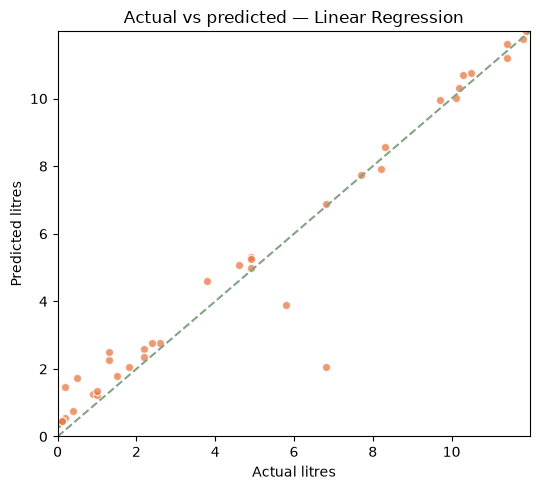

,Actual,Predicted
46,0.0,0.36
137,0.9,1.26
77,2.2,2.59
144,10.1,10.01
114,0.5,1.74
178,1.0,1.22
16,10.5,10.76
19,0.4,0.76
17,6.8,6.88
9,9.7,9.96


In [10]:
selected_predictions = evaluation_predictions[selected_name]
fig, ax = plt.subplots(figsize=(5.5, 5))
ax.scatter(y_eval, selected_predictions, alpha=.75, color='#e77844', edgecolor='white')
limits = [min(y_eval.min(), selected_predictions.min()), max(y_eval.max(), selected_predictions.max())]
ax.plot(limits, limits, '--', color='#83a482'); ax.set_xlim(limits); ax.set_ylim(limits)
ax.set_xlabel('Actual litres'); ax.set_ylabel('Predicted litres'); ax.set_title(f'Actual vs predicted — {selected_name}')
fig.tight_layout(); plt.show()
display(pd.DataFrame({'Actual': y_eval, 'Predicted': selected_predictions}).head(10).round(2))

## 10. Save the selected model for Flask
The entire fitted preprocessing and regression pipeline is serialized in `model.pkl`. `model.py` loads it and exposes a prediction helper.

In [11]:
model_path = ROOT / 'model.pkl'
with model_path.open('wb') as file:
    pickle.dump(selected_model, file)
print('Saved:', model_path)
print('Selected model:', selected_name)
print('Evaluation R²:', round(selected_r2, 4))
print('Features expected by the Flask form:', FEATURES)

Saved: C:\Users\MidhunWork\DSA 2026 files\Flask-Assignment\model.pkl
Selected model: Linear Regression
Evaluation R²: 0.9468
Features expected by the Flask form: ['country', 'continent', 'beer_servings', 'spirit_servings', 'wine_servings']
